# Patch attention on small images

How does a compact Transformer compare with a CNN when data are limited?

I split each digit into 4 by 4 patches and encode them with attention. A learned position tensor retains image layout. The comparison is trained from scratch, so the results reflect a small-data setting.

## Run settings

The default run uses CPU and a small training budget. Set `PROJECT_FULL=1` before opening the notebook for the longer run. Both modes use the same data split and evaluation code. A short run checks the experiment; the number of epochs limits what its scores can establish.

In [3]:
import inspect
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn
from sklearn.metrics import classification_report, confusion_matrix

root = Path.cwd()
while not (root / "pyproject.toml").exists() and root != root.parent:
    root = root.parent
if not (root / "pyproject.toml").exists():
    raise FileNotFoundError("Open this notebook inside the repository")
sys.path.insert(0, str(root / "src"))
from vision_projects.training import (
    Trainer,
    TrainConfig,
    classification_scores,
    digits_data,
    image_grid,
    plot_history,
    predict,
    seed_everything,
)

QUICK = os.environ.get("PROJECT_FULL", "0") != "1"
EPOCHS = 6 if QUICK else 40
seed_everything(1031)
output = root / "figures" / "13_patch_transformer"
output.mkdir(parents=True, exist_ok=True)
(root / "results").mkdir(exist_ok=True)
print({"torch": torch.__version__, "device": "cpu", "epochs": EPOCHS, "seed": 1031})

{'torch': '2.14.1+cu130', 'device': 'cpu', 'epochs': 40, 'seed': 1031}


## Data and split

The 1,797 handwritten digit images come from `sklearn.datasets.load_digits`. Intensities are divided by the known sensor maximum of 16. The original 8 by 8 images are resized to 16 by 16 for the convolutional experiments. Resizing adds no measured detail. The split is stratified: 60% train, 20% validation and 20% test.

{'train': 1077, 'validation': 360, 'test': 360}


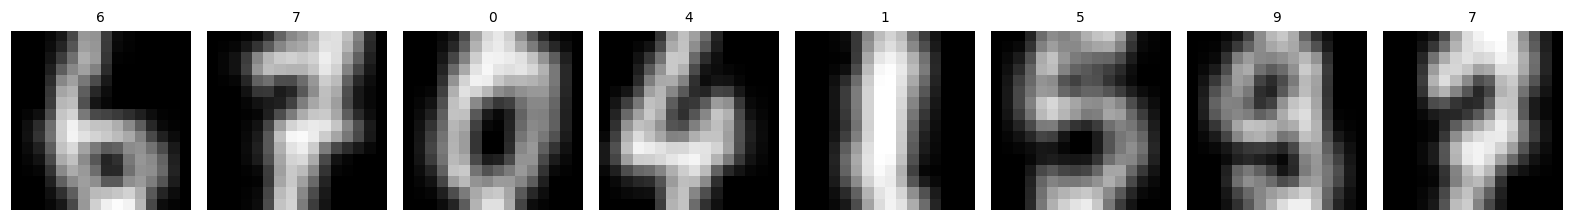

In [5]:
from vision_projects.models import PatchTransformer, LeNet

data = digits_data()
train_loader, validation_loader, test_loader = data.loaders()
train_images, train_labels = data.train.tensors
print(
    {
        "train": len(data.train),
        "validation": len(data.validation),
        "test": len(data.test),
    }
)
image_grid(train_images[:8], output / "examples.png", train_labels[:8].tolist())

## Patch tokens

Sixteen patches produce sixteen 32-dimensional vectors. The convolution with kernel and stride four is a shared linear patch projection. Attention can connect any pair of patches; learned positions tell it where they came from.

In [7]:
print(inspect.getsource(PatchTransformer))
transformer = PatchTransformer()
tokens = transformer.patches(train_images[:2]).flatten(2).transpose(1, 2)
print(tokens.shape, transformer.positions.shape)
assert tokens.shape == (2, 16, 32)
assert transformer(train_images[:2]).shape == (2, 10)

class PatchTransformer(nn.Module):
    def __init__(self, classes=10):
        super().__init__()
        self.patches = nn.Conv2d(1, 32, kernel_size=4, stride=4)
        self.positions = nn.Parameter(torch.randn(1, 16, 32) * 0.02)
        layer = nn.TransformerEncoderLayer(32, 4, dim_feedforward=64, dropout=0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, 2, enable_nested_tensor=False)
        self.classifier = nn.Linear(32, classes)

    def forward(self, images):
        tokens = self.patches(images).flatten(2).transpose(1, 2)
        encoded = self.encoder(tokens + self.positions)
        return self.classifier(encoded.mean(dim=1))

torch.Size([2, 16, 32]) torch.Size([1, 16, 32])


## CNN comparison

Both models receive the same split and epoch count. This controls the number of passes over data, but does not equate compute or parameter count. Validation NLL selects the model for the detailed final error inspection.

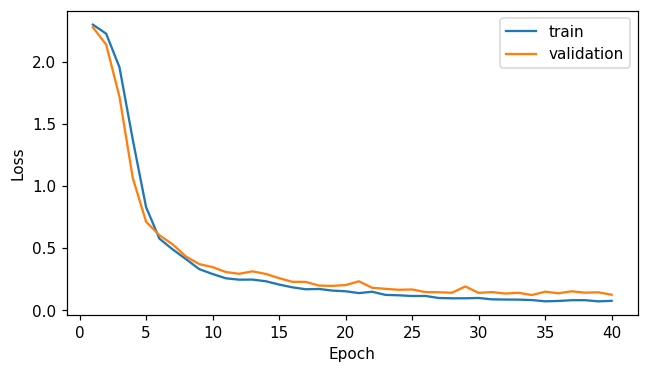

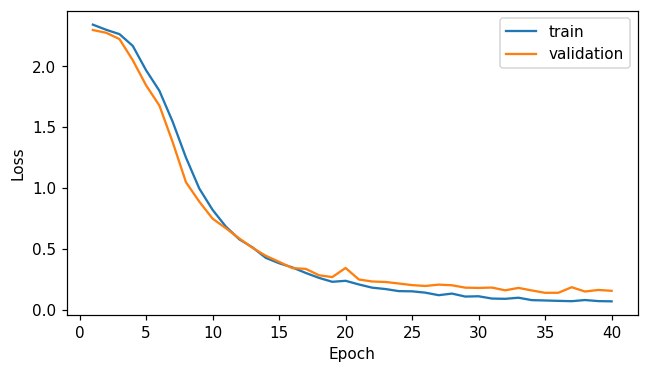

               model  parameters  accuracy  macro_f1       nll
0                cnn       28026  0.955556  0.955043  0.123438
1  patch_transformer       18474  0.955556  0.956045  0.138237


In [9]:
rows, models = [], {}
for name, constructor in [("cnn", LeNet), ("patch_transformer", PatchTransformer)]:
    seed_everything()
    model = constructor()
    train_loader, validation_loader, test_loader = data.loaders()
    history = Trainer(
        model,
        nn.CrossEntropyLoss(),
        TrainConfig(epochs=EPOCHS, learning_rate=0.001, weight_decay=0.01),
    ).fit(train_loader, validation_loader)
    plot_history(history, output / f"{name}_loss.png")
    logits, labels = predict(model, validation_loader)
    rows.append(
        {
            "model": name,
            "parameters": sum(p.numel() for p in model.parameters()),
            **classification_scores(logits, labels),
        }
    )
    models[name] = model
print(pd.DataFrame(rows))
selected = min(rows, key=lambda row: row["nll"])["model"]
model = models[selected]

## Held-out errors

The test set is evaluated after validation has selected weights. The confusion matrix keeps the true class on the vertical axis. Mistakes with high confidence deserve inspection because cross-entropy and accuracy respond differently to them.

{'accuracy': 0.9472222222222222, 'macro_f1': 0.9466941322952241, 'nll': 0.16145541066647487}
              precision    recall  f1-score   support

           0       0.97      0.97      0.97        36
           1       0.80      0.97      0.88        37
           2       1.00      1.00      1.00        35
           3       1.00      0.92      0.96        37
           4       0.95      1.00      0.97        36
           5       0.92      1.00      0.96        36
           6       1.00      0.92      0.96        36
           7       0.95      1.00      0.97        36
           8       0.96      0.74      0.84        35
           9       0.97      0.94      0.96        36

    accuracy                           0.95       360
   macro avg       0.95      0.95      0.95       360
weighted avg       0.95      0.95      0.95       360



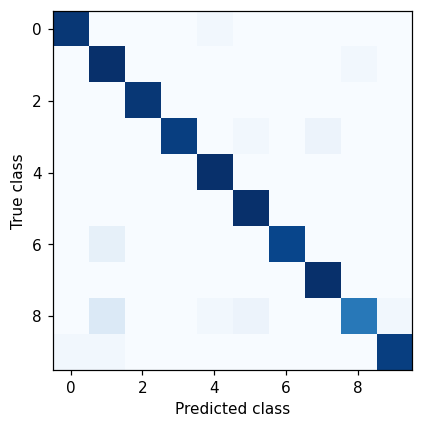

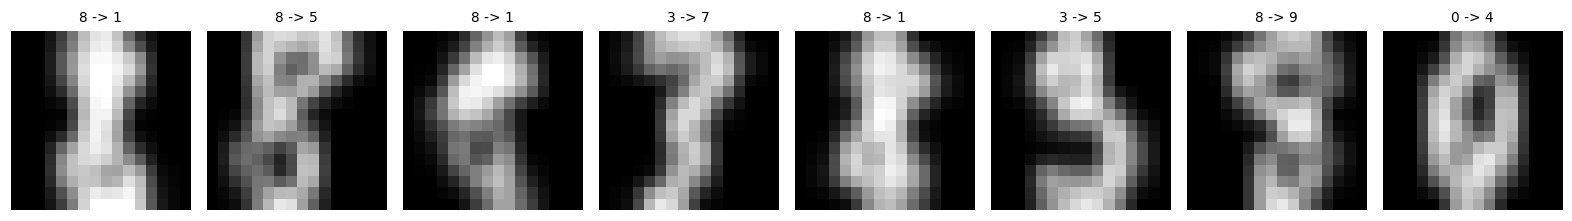

In [11]:
logits, targets = predict(model, test_loader)
scores = classification_scores(logits, targets)
print(scores)
print(classification_report(targets, logits.argmax(-1), zero_division=0))
fig, axis = plt.subplots(figsize=(5, 4))
matrix = confusion_matrix(targets, logits.argmax(-1))
axis.imshow(matrix, cmap="Blues")
axis.set(xlabel="Predicted class", ylabel="True class")
fig.tight_layout()
fig.savefig(output / "confusion.png", dpi=140)
plt.show()
mistakes = torch.where(logits.argmax(-1) != targets)[0]
if len(mistakes):
    mistake_ids = mistakes[:8]
    image_grid(
        data.test.tensors[0][mistake_ids],
        output / "errors.png",
        [f"{int(targets[i])} -> {int(logits[i].argmax())}" for i in mistake_ids],
    )

## Permutation and positions

A Transformer without positional information and with mean pooling is invariant to token permutation in evaluation mode. I check this property directly, then retain positions in the actual classifier. The check distinguishes the token computation from image layout.

In [13]:
encoder = models["patch_transformer"].encoder
encoder.eval()
permutation = torch.randperm(tokens.shape[1])
with torch.inference_mode():
    original = encoder(tokens).mean(1)
    permuted = encoder(tokens[:, permutation]).mean(1)
assert torch.allclose(original, permuted, atol=1e-5)
print("Mean-pooled attention without positions is permutation invariant")
results = {"validation": rows, "selected_model": selected, "test": scores}

Mean-pooled attention without positions is permutation invariant


## Reading the result

This compact model uses mean pooling rather than a class token. It is a teaching implementation of patch attention, not a pretrained ViT benchmark. The comparison shows why architecture, data volume and pretraining need to be reported together.

In [15]:
result_path = root / "results" / "13_patch_transformer.json"
result_path.write_text(json.dumps(results, indent=2, allow_nan=False) + "\n")
print(result_path.relative_to(root))

results/13_patch_transformer.json


## Next experiment

Keep the same split and compare fixed sinusoidal positions, learned positions and no positions. Select patch size on validation data and repeat with a larger image dataset.

## Sources

[HSE deep learning course](https://github.com/mryab/dl-hse-ami) and its [wiki syllabus](https://wiki.cs.hse.ru/Глубинное_обучение_2022). week08_transformers. [Vision Transformer](https://arxiv.org/abs/2010.11929).

The implementations here were written for this project. Course notebooks and their saved weights are reference material; they are not redistributed.